# Batch CDT: exact calibration with fewer counterfactual solves

This notebook accompanies **Batch Conformal Decision Theory with Fewer
Counterfactual Evaluations**. Run the cells from the top to recompute each
table in the paper. The executed outputs below are already cached.

**Two cost models:** (i) a black-box query obtains one scene's observed
binary loss at one parameter; (ii) for parameter-affine planners, a scene's
complete candidate list can be enumerated once. A candidate enumeration is
*not* a unit-cost binary query. The notebook never equates these costs.

Two public-data studies use the OR-Library knapsack and set-covering
coefficient matrices. Both planners are simple linear programs; their
decisions are fractional relaxations of the original discrete problems.
We time actual LP solves, reusing the same matrices for every method.
A synthetic experiment tests the continuous procedure; the 48 overlapping
SDD robot scenes are retained as an additional diagnostic.

The original planner, map, and complete `nexus/video4` annotations are
embedded below, with provenance and licensing notices. A later section rebuilds
the candidate geometry and measures warm calibration runtime, including
common preprocessing. Data/map setup and JIT startup are reported separately.
We retain the earlier batch adaptation: forecasts use two observed
pedestrian positions separated by five frames, not the original trained
DARTS/Y-Net models. This is an offline one-shot planning study.

**Dependencies:** Python 3.12; `numpy pandas matplotlib numba scipy
opencv-python-headless scikit-image scikit-fmm`. The embedded provenance
manifest records the versions used. All displayed outputs are cached;
rerunning recomputes the measurements, which will vary by machine.


## Public-data experiments: knapsack and set covering

We use the 48 published OR-Library `mknap2` knapsack instances and all
ten `scp41`--`scp410` set-covering matrices. For set covering, we sample
80 required rows in each of 48 scenarios, using a fixed seed. The two
calibrated planners are LP relaxations of the published discrete problems.
Both use a weighted sum of a nominal objective and a penalized resource
quantity; a binary loss records whether the latter exceeds a threshold.
The thresholds 0.75 and 2.5 place the cutoffs away from the grid ends.

The script below contains all four methods and performs 11 timed runs
in randomized order. Every method receives the same cached matrices.
An independent audit solves all 129 grid points in every scenario and
checks monotonicity and the exact cutoff. The script and data are embedded
and extracted to a temporary folder; nothing must be downloaded.

Sources: [OR-Library knapsack](https://people.brunel.ac.uk/~mastjjb/jeb/orlib/mknapinfo.html),
[OR-Library set covering](https://people.brunel.ac.uk/~mastjjb/jeb/orlib/scpinfo.html).


In [1]:
import base64, gzip, importlib.util, io, json, tempfile, zipfile
from pathlib import Path
import pandas as pd

PUBLIC_ROOT = Path(tempfile.mkdtemp(prefix='cdt_orlib_')).resolve()
with zipfile.ZipFile(io.BytesIO(base64.b64decode('...'))) as zf:
    for file in zf.infolist():
        assert (PUBLIC_ROOT / file.filename).resolve().is_relative_to(PUBLIC_ROOT)
    zf.extractall(PUBLIC_ROOT)
source = PUBLIC_ROOT / 'benchmark_public_cdt.py'
source.write_bytes(gzip.decompress(base64.b64decode('H4sIAAUa+moC/8U725LbxpXv/IoupBQDMyRE0hpJocUk2l1nbZez1trOE8WgmkRz2BrcjItmRlPzUfmFfFnOpRtogJeRXZXKPHAIoM/pc7+h6Xnez7e5qFKZJKJoNoneTmJZS1Grqq5EvhObRG5vJpv8Tmxkvd2L//6fn8VWJnpTylrnWTgafZsVDaz1myzNY73TKhZZk6pSbwWiChYjIX74cfI9gpT3Ir3JZDFfiBevRdoktY51qrIKUMlE4KMK9hM6q2qZbVUV9oGrbfFiNpnQv+kCqMxEperJNv+oyg5oLCqZFgkQUqpfGl0q2KEGVKP/yuu9KBKZZaqshCyVSHSmZCmKMr8uZVqFQvy8V4CpVteAcaOy7T6V5Q0u2CQqJaBRqRJ5B9jrXIDc8luxK+W2ZhZitdXITfUVbF4BgxWwWdWACh5V21JvAFBW4vt3I1kUIG8SI4m6hp1JB9Ue1mxztdvprQbSSY5jkeW1yEt9rXGfv377DqSRlygiz/NGo12ZpyKKdk3dlCqKhE6LvKwF8JrXvMdoZO+V14UsK2Wv97Lag0bt5Ycqz+z3VNZ7+x0EV+/yMrXXZYugBh0yAQWsB1R293cIbleBVRT3yHtW8OJqq4v7MC8AXH9SFgZUgupwl1RErl2wrcoI6Cr13Wg0+ubrH78WS9rIB+51ArwHIYglTz4qPwgBEiX4XHhs3lGr0wqENorVDviQcWRNz0cOloQVYPISmInYZMP6rvbImoUAif+oQNAZKQ1MOZMp6Ky1QPhGTxzTrdVdLZC+ENWFSAqtcOkSCAAOE137pef/KQ3+/r66MPb2vrr0V39/n60vg/eZNybxhkQvovODgBB12y7Fak23QE9E0xgcOCeHEp904fOWq9liMV+PDQGrOV4ZxvAP9LRB/2iRWYToLIiJUDLJeKvyHWD8o3VL+hdWoKfCD3rP9Y6XyAxcIbv3t3tZhrqKwbSBJ9oKb+FWuC6ghSCkXZMkKUYhENTqfXz5fhK+r9aXIBda1ifC4SQEWaks9ndJLmu/zm9UxrvQV7uN0UHQ0Qp0os8ZLH302zyrddaoTmoRGl1TUvzJIl1jtFiCAxU+hJOxxbJCWY86LA0Y51LMxWULc+miGlxd2FUtBllVCp1GZb7ZIRDLpUF8KWZj4bMduCvG3fOOlo8yaciEsiKUlSxLeW8BwETAXOL6vlBLEmIHBYa608gCg68WhsDOcraykFtd33drzJLFUY47QHvrALAPsJjM1ujwe1ko/5gWHIW2aQViL1oEycba6NgwM253HrfEG6twpN3iInm/eD0e3B0xCxQk2rtuxIHEFVHiOhZyKMOdjjjz6XSyuZ/MptOpIBzyWgmOieQs2zxp0gz+QRZv442rYAyuyHZ27Q9jCmRPVSw94VmNw3Kw4JcvmCWQcH5LwoVNehZuLcAaOO3eKW++mF8y0BrsCzH7ji0VeaUxS6EzmGUsQdrMbLUCK3QCnEbXLWV2TXqHhU4IsJ4FlPmGALvFOviq2+5yKWYd0D6vVNaRbFct7JdLQrsWEwfIsQmGdxwQdYHulCS+PxVvlsKu+L0wi8UbI0kn7iArNmat9PqCcLlBI2kfM5KwzqFq6MUul0GCd+23E/aS6GZ2QfO+fTJ27zNWY15LJ/+C/xRhjhkAV5MGEEmnM7wkx1z6fbvp+xNjC7Psk6WIcLkuxEvGbFTGjTaNTpzMbbRfbVV2PBWedm8ypF4Z4JjS78RfuvoOcHxQ2xp8JFF0bwGk3XEBk0FxBKXxJ6gE7Fa3GipO6aCCsCMT2BCpairwP/LnnS6hRoScAj4pIRfFLY1hC7uRFYbCiYm4z80eYdWkTn4tdXVDJQWDr6ZrWGnZhKt2IYvJBsIHD0XkLYykPNwMrvAfXCFSuMJ/44Mka/68t7iilay3gUu772mgDZhmDCv96RhyEYDVewzleYI3p+Grq8eeFTDRPfVzCK2Uipfz6fzlbDZ7aQ3BJE2wBH/nYUR90I8Q1S4G4bclzoRg/yAGYyWg0TRnQiWghRYbR2jH7QZhCdLvbBaw0EvQNcVeeBTnaQgsSOgPIrhP5AcnrddB+OK1Y5hW1j3fAFDD+EqLZ+RM5jpwUyv1RTETVEFV7QMZIUQTvVW+cUdyXDCZsXg9RaeB+n+rln+RIAGH4553gFA5H4Fhm16KTTvfoNfoj1A/VmTxXFlA2+MgYp9SNn1BC4UrKwV+ERs4XXYtUAqRp8bSGvnu/OQtOgmzsLJ8rode5MYtElsQgObnV0M/YpE+F7Or6VOes/MeWNCPkdt2Rg96MZ3HYHinneCks7FXvT0DCo8nvSBsOMbIO/Suk1hcp5uH53yO2yq6BSlCpsYaudXlmh+bN16xYs7WUK/BUihezV3icH2CnLdRs1mahW9hldg4NzYnwYjVql1HjANwqup9Hi+9vb7eV55pl7isZ5ohfG7BN5zqHgIwmMiPkDKhq/26LPPSt+yQptfE+NjCpwAM1VfQkxl3Gj12xZ8txF0AwtwmkPvED+A6iWorvB+gKdrKLbb/GzBxMO18AwnyI/XvkDpKliCVFdDYAjW1Kqm+IwyooCjSma6jCEJKshsb5Y3FdaljTIDgS2nRgI9FSFW1/L+81zghUGhh6IIB6Wuq0hyjSw/lw2Mf+GALgDi455K7heKoJVePxQeHHNDUB1sRtNQM+jwj8SkGkLeZwLqopFAkdxB8APkG0jkPTySbb4kDrKQLGDcKexOf9na3xvsIprOO//7erI2lKzao1/rkcRzxe47T8rL6sA5wqxOig5iHCjpq8ZSIjsOtkJV1v+duOVgBW2tTGBNxf7Ru2UUB9NiZmrx2ygoTC3pYWI1/BocH06zvW6WieCtSmKMrg6FVJWIJbCYHj6MU4ufkEGMBGtsCThoncsoZg9VDfipNAjrWFXGq2SlZ6U2iyECBzVhBasQhE2ao5N5UXeA+tUYzadKuQ4Ky9zvB5saEGKUGY/ceGaGNJEzU4lQBkA2slVGgrU0ZRZKPxV5jyoJa4Tu6dbvXQD3cnMBTUM+sQ5FqTNk+3L6EBZCyIGcNxxWt3IYDiyThySQaLNSMHSmANTgkvG8/rVSXLiboaG5GrkUOBkH5LXgbZdtPqswrP7M9pXYbGvxrisIupVx2eiUSys5qWk4k2qgGjSqkpt8/Mg6icPLHJfK7YNrAW6mDvfPtpcEZHAd+Y4CJWgOsM99eHgVmdRJ+rtVJatD3ERTfOkKrcVHs1RNZZ3mGEmQyLWwAxdkhoQ5jDpl9bZ9SrUNSX7fAvV22YHsFNH3No7F2t42777UtHGy/5Lo4lb2dJ1NdTO3T/zd6e8MgIkcscQytMqTMetJkFNmtc2uc5vxW//28klxy4QoluT70EpSM69RrGxhwQ4ZkUR5EQi4oAQ/mhxuMuI73/1w2ji8V+mNeRzbbUOTuqnWzSafTNqRMbUR5Iqo8GVkMS4ZPhxq2poHq+1ZxYCwEjlrK21tYnalyLKB2lcm4DRs87hkPx9Akf+Z6cYJEPTbb4IRzYfDbil0HAzIP4QCGaDkJwvZ+exQpoCOtvmFL5M0BY2tHfGfUI+AIBJbNcEWEBAtrNi1fZ+IuIZucRtZb3JJF/NiMbN+SRDuZ6uTeT+RGJV09Cd2gknW1fAUmtpzN/8C+POzAyUnJwaAvqApoH6kTARgm4cZYM75lgjCXY6lNBQJ7LWkP2oZpOMOJm51DUUmPWeyh5cPDVwNRW0ZAGwMl+iaW4hcgbOHUF3B94zRCXpssPxfYrUvQSV1kXAv8dlxtiXMScRtFh4i78MqIKwPO1XlexqqMPi/aYTFZxs4E4nfib9QKxeJWlmlTwIoUWvzKKbm+0f/7zU8CGw+N8y9uV+j9HRamEspMKBZCM5Rp6+CKZgvT8CpoJx1sVl18NWYW9OsrtgBO+4axEPJW2vCLTp9mocZMgqMFGHDHrZfvdjN9v6insAoZR9y7iIaoqhy8ypJZxbHKbLfi/+s2y6FgwY6ZkT5s3PA79OPbgMXX00GnQ5rpBg/smmQK5Jwebw43+AsOE2hfmszhl5MjAOMNTZ3vdhHVzACDrskM4jCB7c1bnEXBjS+1NgzJ/Y0R0xtIz9S3YFfzBC1kKBVQYbI2NRVABo+D8IGVnxlX8B4UF8pVn5U1GxdPeUmIj8PXOQaaZvf40syI1N6m5bXkKskZzXWmaAzASfMNldqr8mBzyhArq601bmnMpv/6gsFXVhQuF4C7W0x0dWYxtIITcoZ1MotaMbPmIDrgbZ/3D07OjLwqPgJa1bGBhOo9znfL2RkMvH2rzf7+xLZ5NuT7CaoOMSJZ5xB2xPYnX0c8jMMF3ujSFNxGg4+KHBwGn33Xp8+rZXmt6kgmxV7SWBsMzKOTIxDSkxyMEKEGo3VjweS6ZDUQLVfWCddISpNCgkbiSP/o7MBMt/7RpHLZxLqOkMI22Km7ggatEe9hcnhXiX8LXoPGpLIaGmbSs1AfVXnPGd0cTqAxFM56d/c4i83rPNM47W/L8afSv50P4Rsyet28Wh3MF/nggUxRWYiPdcelsLbDyXXvbZJ54Qb/Yr3b0ZADeJZ3ugIVY401U5NXDGGaCZeEp2Yip6IWmRTNbFvi8MSF2d2YyvpX1T29sqfNNEe6QmaD+jZic8otR9cfdpLR1RYsTvVC9IFBDLygdXSHxovv2IZ54hQZ/eMYmyqZ0bm8wtta+yx0kte2BWZtO6UmytH3PftezhsfvPULziUS32vf87Sg/NYncCuDJ3N9KW+nPTMxhootH1vkgTUasNlxsNk5sKJEJduYgwd/+uEGKYWbJU65/SNkT2rws/mBYGgSDVkh1hIaqFpMyYNngInCLt72kdFgcOPw1YFnHKeHBM2P5GS8hyOW40EHaAzE7DTEUCYe1YW0r4dvmmG7ECcwQDJ/l3dHLKKDmhmomQM1M1B2GtnuH4GZqsLv4uJPdRPfi18aRS+dKEPLbQkBnMe8LSA1SDxn/P4dxs+GDuC1gdGeDFza8fnJSIlhmWuPFjdCdf6wEKtp+OUV1dFT/HxJ31/R52v6/AN8zsLp7OirE8c/ANUcU9M8/BI/rvAD+rsvQ8D7Aj+u8OMlfrwKp+vH/6TDnk4dZ9PGUW/79WnjN/eu9nTH4dm6Vr98dNAqe0WyXQ9GuXToI+peFT9cXFSDd+ft98cDzvtzn66bpibaaSzP9M0HjYPtY8+An+mch+hsv/srsPV758fB6JtLUqdDeMTOrPYPJ8t8/uGgrD89VB42lD3l2LdkZEyHo1pDUCjj2PSrpm8MDtcyEyukr5vnclc0fNHDYoq6HmJ9wCa1pW2bPb/6NzJ2evJ7CDck3jY1LreDBvzJFq71hEE31x0KhKoE2LQ0F/nwvCqdx2rbq6NediakdYW80xzTptwb8/5viAWaQnxWi3xxYaz6zMadNLGnOuixhsI+G5gdZFU8bK6GmA4aKifpmYiGZ5RArCdKni4aCpYemi1EJ9F5vRA2Sjhm4yNj//xHFQde/0wO7EXmDlv2Ld2UFUI8C+e4i3g2eVXB55cxXfC/3tdnV+FsJ/75D4CY7Tzx7IjM8Phar44Bg69LvmusYY21B15T0D1+qoHXt6F1bSDa6HgGaqB6C9pT4rp/ZsHoxxRBqdSZHb+NuYfsvXnNm7po6v4w5D9RB9iDJ587sLYTRXdaT9wNTxUg3pWn7vayqXBATh10REtxZHOsrbZArYpblCwtG0N43bC03XkPRPPjQjwYTF8w5i/Wjy0fxh3aFXwNK04YvCHJDgvWx6wfrBgQgn18wUnoi/Vi/qJ6bO+1YyJ48BKM/lGYjvCI/hBXD5BnLgAZvgDAy+cT87Qb1dhn9nwOj0sOf9SBZykjzH++/S3HNq6733NExoBD/P2KPerDv03CI3EltLc+nvALr5N843sX5uyefacg6XdPWAYV9yAEDJf2By8h34nA+vC1N7YNnn3WW2a++Ecs2yvKHM8Z5WUPwt4knPQDGTyDWYSR3SyKjuCiX8XAwijin8REkW/uBU9AIpPoWNVezq9eAoqHIkSRLuyPgEJ+4hd8JHxzX+PvO4Jwr+5ifa2qYc10ZhpSoAGyBh6PMaGowLOvjMywuqbjx1U7sT6S4Lw0jxUWqh40V/RbrO43VM4PbtpD91/Zw1Q8auMXE/ak6nM84ecU3N6jY4PhbQl1H5+LR6sKY9BQxSNWshceskr+fZbn/LRoYVwe6kxNc7TlHFsC7721TJN3fpIfQQpjsx92oBoPRaFKoggLGS+KMBRHkRm80y+hcAxkf8QVvi2vGzxp+I6eGPXwMqy/Imme+95kQrMW2I4PbC69qoZEEtVQMntn4Tjs/Xq4Vq4TaqV/AwZjBSgicxpkLMyLq6XpxmA5nTJjBPQPUVR+d0gHrkLifWHHTaP2zSs9HPT8i8MhwKh78Uu5kcAGCZLu0ddg9C/h3/I9WzkAAA==')))
spec = importlib.util.spec_from_file_location('public_cdt', source)
public_cdt = importlib.util.module_from_spec(spec)
spec.loader.exec_module(public_cdt)
archived = json.loads(gzip.decompress(base64.b64decode('H4sIAAUa+moC/81cbW8bOQ7+3l8R9PPWJ76IpO7+wgJ3uK+HRTAz0jRGE7uwnd0Wi/3vRzmJm7RrJ9vG0iJA4kgzGj0i+ZDUUP79zcXF25uyG/KwG97+8+J3/99bPn7eXa1X/v9bWgAugN/+dN9xPezm9eamdv28XN1+eicLsEXUd59MLoXf/bbcXb17f70cJ1wwHG7brKey3a439b6HxtXtzcfPtQEXtIgPrdtpedcKC9BFeGiu89uW3eX2asAoh5l6z3rjT7u8+bAaPuJi92lX752D5UCRJx2SjuNc5jhKSDZkKuOQhHBOgHMYlWKeR9QkIINQNAoF4nj/1MPo2+kjw8PgcZimnCXkYYq5ziaGPBZJxYYiygyURhlGhVEioEQsxbtYCDhPkIcvg++HDQ/jio5q45CTjzXTrHFGxQKACjTV5nE0HgI4qMJjnTsi5pxiIZlHwKfjHtaCFXIpAjZGjFPxZYBZaIYcJsyafcA5hiEFbxknM5k0FcaJudgMYaSnw9Jh2ECj+UA4mT9hmuY5zzGqhUFtNpQicRxBRhnHwdSXCCloUdGSE6U0Px2WH4ZF8ImkAoaFIEt2oZGMQ1DVLEZgBV2iGLI/Wr3d1LwNxkFsYrOvFjc+DJspjjZhkiFQnsk/ZIhJRsvA8zSOUmbMllxEM0158iuzSBZiUpzLFJ8OKwdVcEh5QjXLUymhxDCPU/RVm3QSdqHDVFKpOuCaEDHzNBCFYQzZeFb+ahH0YVizebA8u1qlKUiYJ8EJi3GJlIZBZxlmY4tzECkpu7Zx4czJZBiGebKvZmsPwyZf2zDnMRdClQnR0D9H1+TscsvRlRrGHNjXddLMPufMcyJf/zxw0q9mmx6G1dGhxCG7QeCUKVkKROqrUNC1ObMvRtKSjB19mnDSEGc3ldFcdlQGersf9Y8H+y8l+6gYUABA7ls35WPZLXfL9WrrnQD3zTfrXK73XPSfi025Hj4N+0su1vPFv//77ufluBk2ny+Wq+1uWDkB/etiXK5qy/V6uy3bi3mzvvH7tuvbzVT+Ma23u4vdlf9/tb7O2zqt/aTejmU1Xd0Mmw/12f/bP/nAPvNws7ze81UloO0wfXi8SmVV6j1sh7b3m2W+/LhernZ7IJgOPbth894Jbrj+eFWZOCzg0DVcX69/K/nybtreSYeu6Xa3nuf99YTmSvbl6bc3PufPhyk/nvbd4hUn+byny9vr68txuS1TXb4DgPurhtXldn39692DSRbhSf82f+kNX/Xd3Vum9SrfdWMKCSsTgrnlin4z0qNrQ2DX0ADJTT8A+Y2Hi//46TlEU9nslvPS1+xFsCDaj8ACEgvEzl0pBKcqOY0Lycx/a+QEpKD6F4C5Hl+tNy/GlX4MlzrDSHK6DGYGQs/gckjRacNUKZDQ98DaluuXwPLIIH35gaMQoy5SjO5wSH2h3fc9A1gUXC+ZFSU5kZ0G7Ozv4uMghv4p8he8959+ORjj5na1PW6JJ0jkL4q/8uRQWfmpZO9Y4nK5yuVT5SN80ns93DjD/wmH3KF+pExPO55oCsHeW6ak0aUvz8r+OzAf0Y2zYrZwHHPkEBNDtXn3vek1MT/LX2cFHU8ImoE99ANIVdKmr4j5lBc6J1z3aUfhYkLvRoDgLsg46Dn0+jnM0NqWHWdyY05J9CVu95VFDK1FHIkFmVOKAaQLc51DwnxCwp6xuOMSceZCiBC7MBc0Zi5yoCFWuiYE64MZW2NmUSJX7RRNOHZR7rNgphPKLcEzDGJPIDzxTs1dFDbmLyOPRMDMHTKaGPdwUdjYRYl4yoUxVAIjpC56Tecg7RPhJiQXr6eXezmbURcCo/akzZ7ASQ03k39sbczU2pgdLHOsxkzniUV6SPikKasaaVCPsNOryvfFhsxnQKwnEMegnjpqlTF43Nlcp7l5DoUYOaJLWClwn8iLWxOXQ9V9mpwksHZJHLl14hgUk3mInVTZ2LoIOjb3UEmih10uZ6J4HkE/x2CxdYjtTJ08h3TMlnyUHsodW/uplCg6k9V9YScybs3asTVre66MWiMRd8+ceohY2osY3C97KBKsvgPowl/Smr/Mpewa7d4Z9FU3sV+k1tI6wLbIhFwTCv/Th67PgNlp6TjmqKgWg5syY2Du86JCO+g1hVR9lII0p2ttTtcAppTcjKW+h+3B19o63qzbA4FrYkEee3VJHs+AGUM89XKmls14ThEkElmX0MuayxnYgxGXMzmLKbW2ZWtty+LuWMH5mtQDkR5qfQ7IIZxwUbWAJoa6o+uJBXIXF2XNXZQGV2yPRVTUfXQX0Kn5xoh3Q6g7I6R9OPsMkJFOxF8BPOhSDnXDL1nz/b7UnL7cNaF6RhHB468eHiq19lDoppxqDYHgq+57vaxionVVjHlMHaVu9FmMAfpUxYT2uwMVrkch6PodoE/RROt6LzdkJiY35hAFrQtfnwW0ntjfpLo5ELhuBCWAx07qm8rO8ulquN3ulr+Wy31t93Cbl7tH51MeP1MgPZprLeu+3Cy3H7aXN+vVerdeFb9mt7ktj675BuubxxO5l8GfVKPXszLT+tey6VaO7jGsK8zfux7d/XEMTIHBQJTwZLmvq5K7cQ/XEEWRQc5Yjw7xR2ARsYgnTWZgkQSeqbNPApzIAQVDeIH3+u5qdKEfQSVssb4V9zwh1gMmp4XlduuYIqoLK8HZStF9wRYeuT/6OV6LjotaMe50ElRqVelpuFbF4jlTPTNhGE/qJgIKxVohooIBH5epfncp+rcMcpZadNVj7P0VgXxF33KcvoUDsodhYb9foH8lHHs56B8qRv9O0Ih8FHSqWdX+AF5AEsHXBP1K1ejfK2o4vh3mTBeEJXlQxqBCr4n6x+vRvxPwqdDb84t69E+cGMCSyVl0+4cqd89h0GT11RTEGoAjY3MpQ3MpJxev1mMHnkcbdmGws0iZ9SjomDClqLUuKrFIHwKD5gTmnts8KtgfnJLIfWBjc9gh1dhmL3Fm0i4afhbUAsd5zNONCAGdx4RjaO+tsDWPxWTs4Wjd7K25Uxdvhe3DTyJPVeyuZLkPedNZwk88FX56/kyJ6/tnTbEPjVFzGqv7B4n3xTMemjQ3aGpt0DVz9Zudt8UjMe1i0NTcoCEQxkgefrrHki4Gzecw6HRMtWGBdTtIPPasLCaJm6s2N1VtqN9fEIMieQJdv3KnU/zJPQKxWmhQj1J5ksVdLJqbW7TLOqZ66ATZtNNmSWwvazZ3VY6anMmgC4/F5lnlXrHr2+iQNPTZMIntN0yC1HLP+go+YmxO3rH5hkn0UMyEaqKB0CcukfaJhofaqp5OJvfWnWJuaR9zO3kLek4ZGdvn0NJ+x1djdMR100Cxz9uMc4DGo2/gPRgzEwFmrm8zYifN1vaabYBWQ+56pEybq7Y2zyaD+ym/uRZwM1sX1tbmrC2BtH61XfA0uo85nwMzhuNVRKl+exKo1RIq91XYRdDWWtASPc52EdfIEwM0N2drbs51e1vqu0kPwSh1Ue1zgMaoxz0Vp3o8smYZtTSok6uy9qkkBYv16A27WTP1gZ06lBsASD19g3UE6qLiqbGKQ9AICWsGTa7r0pzIUvOQ25NmjbWcWy0odHFXqX02aZZC/dq/+pW77aUMzWtpjB1uPTRZy307ldK0Lo7TUKvEYrj7ko5emwbQvFBMiNys616J1Ti0D3OfB7YerziwYBxxH3d7WgnwtylkPxy8vy9k99+/vPnjzf8Bq10ttJBiAAA=')))
archived_table = pd.DataFrame([{
    'Problem': experiment['family'], 'Method': entry['method'],
    'LP solves': round(entry['mean_solves'], 1),
    'Time (s)': round(entry['mean_seconds'], 4),
    'SD (s)': round(entry['sd_seconds'], 4)}
    for experiment in archived['benchmarks'] for entry in experiment['summary']])
print('Recorded measurements used in the paper:')
print(archived_table.to_string(index=False))
public_cdt.main(repeats=11, audit=True)
public_result = json.loads((PUBLIC_ROOT / 'public_cdt_benchmark_results.json').read_text())
assert all(b['exhaustive_grid_audit']['all_risks_monotone']
           for b in public_result['benchmarks'])
table = pd.DataFrame([{
    'Problem': benchmark['family'], 'Method': row['method'],
    'LP solves': round(row['mean_solves'], 1),
    'Time (s)': round(row['mean_seconds'], 4),
    'SD (s)': round(row['sd_seconds'], 4)}
    for benchmark in public_result['benchmarks'] for row in benchmark['summary']])
print('\nMeasured LP calibration times:')
print(table.to_string(index=False))
print('Audit: every grid point was solved independently; all cutoffs agree.')
print('\nQuery counts at alternative risk thresholds (LP solutions reused):')
sensitivity=public_cdt.threshold_sweep()
assert sensitivity['set_cover'][-1]['anchored']<sensitivity['set_cover'][-1]['certified']


Recorded measurements used in the paper:
  Problem              Method  LP solves  Time (s)  SD (s)
 knapsack      full_bisection      336.0    0.2909  0.0042
 knapsack certified_bisection      158.0    0.1368  0.0024
 knapsack  anchored_bisection      198.0    0.1707  0.0023
 knapsack  anchored_selection      197.1    0.1672  0.0507
set_cover      full_bisection      336.0    0.9715  0.0125
set_cover certified_bisection      115.0    0.3347  0.0096
set_cover  anchored_bisection      163.0    0.6486  0.0191
set_cover  anchored_selection      214.7    0.8961  0.2126
knapsack: 48 scenes, cutoff 0.328125
  full_bisection            336.0 solves   0.3038 +/- 0.0089 s
  certified_bisection       158.0 solves   0.1429 +/- 0.0036 s
  anchored_bisection        198.0 solves   0.1781 +/- 0.0075 s
  anchored_selection        197.1 solves   0.1782 +/- 0.0566 s
set_cover: 48 scenes, cutoff 0.6015625
  full_bisection            336.0 solves   0.9903 +/- 0.0275 s
  certified_bisection       115.0 sol

In [2]:
import base64, gzip, json, math, heapq, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = json.loads(gzip.decompress(base64.b64decode("H4sIAAUa+moC/+3d324U15YG8FdBvm5q1v+1dub2vMFcjiLkgE+CRABhyIx0dN591m53FyY0E4cuA4YvyrLNr6u6q8tb2/X1rtr1r4vrV+/ePL26+Oniv/7xj0cvr/733fV//PH82dUr2z2yevTqj6s3Ly5fv37+8tdHe350/fLy9fVvr95e/+ejyzdPf3v+x9WzR79cvn3626PLZ5ev316+ff7q5cXu4vLF698uL36ihXcXLy5//+XZ5ZNf3zx/dvHTf9NCuy7KYvH5E3vc/CBqmvuf9PCQDjo8ZlE3D/n60+GRXJden7F8HJ7o8J3XF+GVOPnmiW5WYpXD6myHp2arwwata8f62Lp2jsMGHWH4YYPkuGWyvqocFhKJw1Oub1psffDmy/HtvF8012WPD9VxB8lxK3TdVYcX13Uz1neoetxBxydUP77F9w/F8S0e/l3r6scX1XHcQcfdYuvOW9+NrZt2XNaOO+j9D3HcQceNtzy+6/WXYOP4lPtaf93rpvu6L4/P6+umrs3G3/90eGRtQOse97UBHb/H2oDWLY21CRweWHfv2khi3fbjm4n3j61rrw3o+G1tQOuW5dqAjmvl2irWRpHrLj98Ob6ddVfm+2WPD60NaN2KWhvQYZlaG9DaAmptJcc3WOtvYd13tb7Fw9f3qx9ftNYGdJSxNqD1tz3WBnR44rG2m3VPjfXXsi67vuv3r3F4Sl7o593Fm1f/c93d0b8u/vnm8vfuAFm9u6pX19dPLp++fXf5Yt9VefZvTMWtd65J8E2bEtF+lbmpY0+E+jHr50OLuX735s2rXy/fXqHRoO7QaH59dfniyetuMm+uuvX83q2G558okVJ2U9URYzdJiSm9O0fj2Zk9nkcZ/ZfPK4JDKfpQBwgEAoFAIBAIPB/7IPXlu9+f/PPq8vr5Ly+unjy9fPns+bNOOJ2ZOU1vHv7t3YsXT66vfv396uXb6yfPXz6hJ3zxk/579z5Vz0X/nKot02zk/AhOySX3H1YRVTGppFgVGZICYvWHsRqtBrVVrjaeow2uo7q3a1qyU7Z5qvVSZZUgEAgEAoFAoK1os2TpfCJZqhVnUCeCYVa6O0k4XEawvB0s0WhQG+XKD+nxzXlQc8jf+ltVMgwGg8FgMBjs+7BzYq18EGvHqQFTcbY0lmIKG7E/K18j2MOFOlcbIgpy7UcDpmg1qHsaMBVTi6FswyU9cn9FVq9lpMISJWPs8+9gczGqbowqVrF7zPNyKoro1ccwctVzbfbDkS5BzmwQCATyNaX/xf1ntphpdNensHNNFh4hZDLS+2+QlcFg37udkyrH7VSZfjJVhjJleBKF2/4SaPeyqHl5fvUB3LwWOuY4WI4+qhMNBAZEzNuXun7cOu5G2KcInH/nytexxDAJ79TXfWP3kbO3pI6W7Nzx0kZSTUq9yZlZ1AsmCAQCgUAgEOiv6ZzM6bcyp1CemlCJ+ogtWUYp6X7YwIcbu3Q44IqqupnqS5lNaFC5he0nmuqf5lEicTkHDqcRQW8i6McN4/MEuxhp9G+k0WxQ6R4ryl12tZSkFM/TQoZW8PwUW/p79dN4yvAxxz7xNwYEAoFAIBDoPtNo3E6jfGp63/AMjRKbV/nJzUytopkk8zTJCMvTZHMky/q4TqkPBF0Pk3w7d5Kd57t1aEWmQDxFE0N9K2fsfkxjESrq5qXdvrrV+S4XZRZnddVk09jPL9/BN9KiTLplyv6kXqkc5E6dfanX2J8EJxxzcut+NjGd08qdNpw+BoPBYDDYwzLrg9l5WBqDQy1AX4/OycVMt4Ox8slhWiFx6eiiIVz7uwF16EileT1X9bHg/g4/kZU0Ot3MYY+7E8foI8/w0IwcbvUJo/lhQGaNPmTVeebf/lZg0ssMYu9N7Kfd30zMxUlLiy2o37050sIPNw78uY0RTRb1DQV36cbk1Y2pM7lJdUofEXPG6244WtQ9+11EF2LNtAqx0UB2iuY90cjnp1NK0v38nvoPwjzXOkVMaDbtmfjTLccI0yQNt7FP996tuXN29uq99Ccoaa6aYkTc7dzPtblp8wSiPjqJZjltOL4CgUAgEAj0xSP27TmdJPTU2HOF2RySYcvYH3k5DQmqPiKkYTdxQjtqz5ixH7OR+hT1kUQfLQb3AaNxH0vimBuRGE0M9a2eLn2nE6j3N1CvyNK0jnZjH0Sr2y+P7qmtPGbSnXNCWUgvOrK/cD/b1zTMgwOBQDA7FQwG+xK21SxRyieGgnHwiwP/E9kSuwbN4nNvi/Mpou6rXNyDU/RvkIaRdVAUJqGvRdLBtGgOnmbHUxAIBAKBQKCvRudkQ/sgGw5kQxSyIWrjscJvIbyBQCAQCATCR6DIhn+VDfV2NpRENkQhG6Luf9zwcwcJQSAQCAQCgUD/L52TDW9f+6imyIYoZEPUttlww4/F/jzlDggEAoFAIBDoQ9ps3DAd2RCFbIi672z48ayqERWkc55r9pDcULSGZb8+t5jZCYmFxWqePWNZJqx+R/Klst+Uh0q/tRCFQCAQCAQCuZFzAlreDmiFwTsUAhrq2x28A30hkv4Dw5X9H3ceVRAIBAKBQA+HNhu8G5gsFIVsiLrv+x/GEIqR5BxunUU+T3LhHJJanWko3fhOEkvUUCdh9t7KyBZT7+7UKc1q3uATAoFAIBAI5Aw5J5zFB+EMs3WiEM5QD33gDh/agUAgEAgEwsDduQN3xrjqDoVsiLrfgbsTFAuPcHbRUSOSx2biyzAZIZJjlFcWBAKBQCAQyH3LVvfZM8EldyikM9QXT2cnyLqbqyJOz/3sJgyBQCAQCATyUGSzwTPFVW8oxDPUF49ntsRw1mAVD+0ff3AxyxQLYiEzEggEAoFAIA9LNhs8S1z2hkI6Q2182ZuG0ZyIX5iEdKdLFPOQ/p+slx8QCAQCgUAg35NsNnRWiXCGQjhDbTt0Ft69EJuNYmPptQdRJ7UxRETn9bMgEAgEAoFAoK1oq2zojIE7FLIhasNsaEuVUBCTu3FZtLhSWcnQ9KIx7igk3UEpqUV3epXRW8FarvOZPZ1D02Bn2uNGdq5hHlSS8zsQCAQCgUDgN4Vb3azBFRNyohB+URuGX188qcPqMKmhVnxS+icJSu2y0bnWF9KwCM6IXloRfhF+gUAgEAgEAs8Pv3k7/BrmO0Uh/KI2Db9q2r1Up6shkuUngu1dBOEX4RcIBAKBQCBw05Ffx2yyKIRf1MaXxLpZDu3kGlrmu1zIO3SNTlvdOyXxCUH6RfoFAoFAIBAIvOehX8dFvyikX9SmQ781XMaInDP2dod18iznvz7vWZdMUZ/92fBw8URYRfgFAoFAIBCI8HtG+C2c94xC+EVtO/RLRGN2WTSSOtDucrm5YeYwGSFeHwOyL7IvEAgEAoFA4P1m3yDcCQiF7IvaMPuO7q9oSEfWNAkN39XS/ZYUm3Q3phV8MupKRJi42EjPGLGTRdxZWEgqirNmeBMebjEGcS9JnPv+UXSYiVUn7Tkd/vgkamaIppKb1/z69TGUde4M0iwOhj1gq7JR3e5F1LrFBwwGg8FgP4qdk02Zb4dTxTW5KIRT1KbhNJIptZNoRLnLybhKMa/ZJbJIZcFZyRiFBQKBQCAQCLyXodn6IP3imlwU0i/qC6ffWHzed1fdjJh6ZaRfpF8gEAgEAoHAe0+/ibFfFNIvatuLcl1jzCg7vMZOFjbqzEskvdA8P3nHS3UvZVYkxNy5+KSEdH9HQdFPryQIsAi/QCAQCAQCEX7Puio3MfSLQvhF3Wv41WEybyqUSuHG83pblqxI4hERLjXDr4+OauXSKyYVnyIkWKRfIBAIBAKBSL9npN/CnFQopF/Uxrfi1aEdWVXm2c61G8uIov53sFoYzbvsdhAmUSMbmSUnT3PGmc+Iv0AgEAgEAoGbxt8k3I4IhfiL2njwt3NvB15Rju6v4rsk0QwvtyIPm8PXIBDoEzSWiArSnFc2eEhCIBAI5EbOiXR2O9IxzudFIdKhNo50dyTqvsrFPThF/wbNm5tYRQp3j/h36AeImiAQCAQCgX482iwbCs52RSEbor7GcB+GF7YRrWHZ+5ZbzAwCgXwn8ri7NplTwCXTUNOIeAjW/XDICCdOGUYGfCCYqiXDpcyLxQv2MG2rqXBTHQkRhYSIuu+E+BCC3pc78JvXKg636H8LJZtrwGAwGAwGg33Ldk7+jNv503ErFhTyJ+pbyJ8Y14NATgmHmNrgrgQAAIAHCRqdXsL76GBI6rcmm83zEjjxE4VYhdowVt0l1dhCYyiFMlF5P7jTpXohVvXhPO8JAoFAIBAIBPJQZLOL8gpzcKKQzVBb34Licwaz/vxRf3d7FlSDbfSCTpY7WSq7B9S0FKKQqDvTvCEk5wirEiZXEAgEAoFAoO+Cthq0K8a1eCgEQ9QXHrT7OAXmouHJ3inOyJwSAoFAIBAI5KHIVoN2JRi0QyGboTYetHOlqiHBnJm7WjQzQj3GSOHudHIJngNrLkTe65bfmfBnAAKBQCAQyHcWz/x2PFNMI4JCPENtOnRmQ1zmWZCqxDlOxyxmSSrmET4qaxdLea+u0quURTEEAoFAIBDIQ5HNwlkinKEQzlAbhrNYOpvVqNJM9qEQCAQCgUAg37mck83kg2w2kM1QyGaoLbNZKHPG4EguLm3RLGLvkmJWmeIaRu5RljryjsJiZRVpWSasDgKBQCAQCPRj01ZDdkNO3D8gR6kx6aAaLmo4JEZK/DglopWgPic0ytJA3Yd1m+l/85hTLXEM7R4uzUslHQKBQCAQCOR7knOim96Obn5iRG+IWWl6v1yxeOHAFNHt4+iGVoL6vOhGw5XNg8foppO546WM541TSrI7uhoBAoFAIBAIBNqKzkuOP//7/wDwg34LHrQCAA==")))
rows = DATA['rows']
lam_grid = np.asarray(DATA['lambda_grid'])
loss = (np.asarray([r['loss_actual'] for r in rows]) > 0).astype(np.int8)
progress = np.asarray([r['goal_progress_m'] for r in rows])
n, J = loss.shape
alpha = DATA['alpha']
k = int(math.floor((n+1)*alpha-1+1e-12))
assert (n,J,k) == (48,129,3)
print('Embedded real SDD cache:', loss.shape, 'binary losses; k =',k)
print('These scenes come from one temporally overlapping video sequence.')
print('Execution platform:',platform.platform(),'Python',platform.python_version())


Embedded real SDD cache: (48, 129) binary losses; k = 3
These scenes come from one temporally overlapping video sequence.
Execution platform: Linux-6.18.57-x86_64-with-glibc2.41 Python 3.12.14


## 1. Black-box calibration is selection of an order statistic

Let `rho[i]` be the last unsafe **zero-based** grid index for scene `i`,
or `-1` if that scene is always safe. When each binary loss curve is
nonincreasing, the CDT cutoff is the grid point directly after the
$(k+1)$st largest `rho`. Here the fourth-largest last-unsafe index is 3,
so the answer is grid index 4, or $\lambda=0.03125$.

We implement full bisection, certified partial bisection, anchored partial
bisection, ordinary threshold Quickselect, and anchored randomized selection.
Every algorithm is checked against the exact sum on the stored grid.


In [3]:
assert np.all(np.diff(loss,axis=1)<=0), 'SDD binary grid is not monotone'
rho = np.array([np.flatnonzero(row)[-1] if row.any() else -1 for row in loss])
rho_sorted = np.sort(rho)[::-1]
jstar = int(rho_sorted[k]+1)
assert jstar==4 and lam_grid[jstar]==.03125
print('Last-unsafe indices, zero-based:',rho_sorted[:6])
print('CDT cutoff: lambda =',lam_grid[jstar],'; collisions =',int(loss[:,jstar].sum()))
print('Mean goal progress on calibration scenes:',round(float(progress[:,jstar].mean()),6),'m')

# Internally use aggression order, so rows become nondecreasing.
z = loss[:,::-1]
truth = J-1-jstar

def certified_bisect(z,k,anchor=False):
    n,J=z.shape
    memo={}
    if anchor:
        for i in range(n): memo[(i,J-1)]=int(z[i,J-1])
    lo,hi=-1,J
    while hi-lo>1:
        mid=(lo+hi)//2
        low=np.zeros(n,int); high=np.ones(n,int)
        for i in range(n):
            pts={j:v for (r,j),v in memo.items() if r==i}
            le=[j for j in pts if j<=mid]
            ge=[j for j in pts if j>=mid]
            if le: low[i]=pts[max(le)]
            if ge: high[i]=pts[min(ge)]
        while True:
            if high.sum()<=k: lo=mid;break
            if low.sum()>k: hi=mid;break
            unresolved=np.flatnonzero(high>low)
            i=int(unresolved[0])
            assert (i,mid) not in memo
            v=int(z[i,mid]);memo[(i,mid)]=v
            low[i]=high[i]=v
    return lo,len(memo)

def threshold_select(z,k,seed=0,anchor=False):
    '''Randomized exact selection; count each distinct (scene, grid point).'''
    n,J=z.shape
    rng=np.random.default_rng(seed)
    memo={}
    def q(i,j):
        if j<0:return 0
        if j>=J:return 1
        if (i,j) not in memo:memo[(i,j)]=int(z[i,j])
        return memo[(i,j)]
    if anchor:
        for i in range(n):q(i,J-1)
        active=[i for i in range(n) if memo[(i,J-1)]]
        if len(active)<=k:return J-1,len(memo)
    else:active=list(range(n))
    rank=k+1
    def first_unsafe(i):
        lo,hi=-1,J-1 if anchor else J
        while hi-lo>1:
            m=(hi+lo)//2
            if q(i,m):hi=m
            else:lo=m
        return hi
    while active:
        p=int(rng.choice(active));pivot=first_unsafe(p)
        small=[];same=[];large=[]
        for i in active:
            if q(i,pivot-1):small.append(i)
            elif q(i,pivot):same.append(i)
            else:large.append(i)
        if rank<=len(small):active=small
        elif rank<=len(small)+len(same):return pivot-1,len(memo)
        else:
            rank-=len(small)+len(same)
            active=large
    raise AssertionError('Selection failed')

bisection_rounds=0; lo,hi=-1,J
while hi-lo>1:
    bisection_rounds+=1
    mid=(lo+hi)//2
    if z[:,mid].sum()<=k:lo=mid
    else:hi=mid
assert lo==truth and bisection_rounds==7
cert, qc=certified_bisect(z,k)
anc,qanc=certified_bisect(z,k,anchor=True)
quick=np.array([threshold_select(z,k,seed)[1] for seed in range(300)])
anchored=np.array([threshold_select(z,k,seed,True)[1] for seed in range(300)])
assert cert==anc==truth
assert all(threshold_select(z,k,s)[0]==truth for s in range(300))
assert all(threshold_select(z,k,s,True)[0]==truth for s in range(300))
bound=n-1+math.ceil(math.log2(J-1))
print(pd.DataFrame([
    ('Full bisection',n*bisection_rounds),
    ('Certified bisection',qc),
    ('Certified + endpoint anchor',qanc),
    ('Randomized threshold selection (300-seed mean)',round(float(quick.mean()),1)),
    ('Anchored randomized selection (300-seed mean)',round(float(anchored.mean()),1)),
    ('Worst-case lower bound (not instance-specific)',bound),
    ('Smallest cutoff certificate (known cutoff)',n+1)
],columns=['Method / reference','Unique binary-loss queries']).to_string(index=False))
print('Anchored randomized selection 5%%-95%%: %.0f-%.0f' % tuple(np.percentile(anchored,[5,95])))
print('One candidate enumeration per SDD scene would be 48 enumerations, a DIFFERENT unit.')
assert qc==235 and qanc==98 and bound==54


Last-unsafe indices, zero-based: [9 4 4 3 2 1]
CDT cutoff: lambda = 0.03125 ; collisions = 3
Mean goal progress on calibration scenes: 5.822676 m
                            Method / reference  Unique binary-loss queries
                                Full bisection                       336.0
                           Certified bisection                       235.0
                   Certified + endpoint anchor                        98.0
Randomized threshold selection (300-seed mean)                       110.1
 Anchored randomized selection (300-seed mean)                        96.4
Worst-case lower bound (not instance-specific)                        54.0
    Smallest cutoff certificate (known cutoff)                        49.0
Anchored randomized selection 5%-95%: 72-120
One candidate enumeration per SDD scene would be 48 enumerations, a DIFFERENT unit.


## 2. An instance certificate

The preceding infeasible point has four collisions; the cutoff has three.
A certificate that **already knows which two adjacent points to test**
needs at least $(k+1)+(n-k)=n+1=49$ observations: four unsafe
outcomes at the first point, 45 safe outcomes at the second. The 48
evaluations at the first point and one additional evaluation of the
pedestrian scene that switches supply exactly that certificate.
This number is not a query lower bound for an algorithm that must first
discover the cutoff.

The grid cache alone does not include every continuous optimizer switch.
Section 3 reconstructs the complete solution paths from the original
planner and pedestrian positions and measures warmed runtime.


Infeasible cutoff predecessor: 0.0234375 collisions 4
Feasible cutoff: 0.03125 collisions 3
A 49-query witness: all 48 rows at predecessor, then scene 5 at cutoff.
Video gaps exactly 8 frames: 23 of 47
Overlapping 80-frame forecast pairs: 181 of 1128


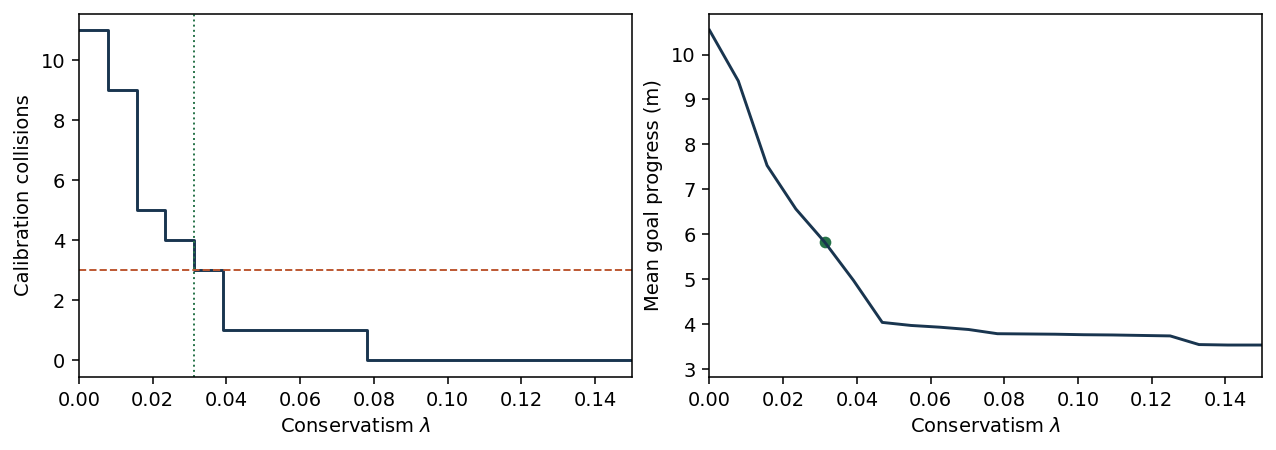

In [4]:
prior=jstar-1
unsafe=np.flatnonzero(loss[:,prior])
switches=[i for i in unsafe if loss[i,jstar]==0]
assert len(unsafe)==4 and switches and loss[:,jstar].sum()==3
assert n+1==(k+1)+(n-k)
frames=np.array([r['frame'] for r in rows]); gaps=np.diff(frames)
overlapping=sum(1 for i in range(n) for j in range(i+1,n) if abs(frames[i]-frames[j])<80)
print('Infeasible cutoff predecessor:',lam_grid[prior],'collisions',len(unsafe))
print('Feasible cutoff:',lam_grid[jstar],'collisions',int(loss[:,jstar].sum()))
print('A 49-query witness: all 48 rows at predecessor, then scene',switches[0],'at cutoff.')
print('Video gaps exactly 8 frames:',int((gaps==8).sum()),'of',len(gaps))
print('Overlapping 80-frame forecast pairs:',overlapping,'of',n*(n-1)//2)
fig, ax=plt.subplots(1,2,figsize=(9,3.1),constrained_layout=True)
ax[0].step(lam_grid,loss.sum(0),where='post',color='#19354f')
ax[0].axhline(k,ls='--',lw=1,color='#bd5832')
ax[0].axvline(lam_grid[jstar],ls=':',lw=1,color='#267349')
ax[0].set(xlim=(0,0.15),xlabel=r'Conservatism $\lambda$',ylabel='Calibration collisions')
ax[1].plot(lam_grid,progress.mean(0),color='#19354f')
ax[1].scatter([lam_grid[jstar]],[progress[:,jstar].mean()],s=25,color='#267349')
ax[1].set(xlim=(0,0.15),xlabel=r'Conservatism $\lambda$',ylabel='Mean goal progress (m)')
plt.show()


## 3. The original SDD planner: repeated timings and continuous calibration

The archive embedded in the next cell contains the original spline
planner, obstacle map, complete `nexus/video4` pedestrian annotations,
the archived batch grid, and source-attribution files. The benchmark
source is embedded separately. Both are extracted into a temporary
directory when this cell runs; the original files are left unchanged.

Five methods receive the same reusable calculations. In every timed run,
we construct the feasible candidate trajectories **once across all 48
scenes** and then compute their scene-dependent scores. We memoize each
scene--candidate collision test. The first three methods use the 129-point
grid; the last two calibrate over all $\lambda\geq0$. Comparisons of
runtime savings should be made only within the same parameter domain.

Timings cover the warmed in-memory calibration, including fresh candidate
construction. Input loading, map creation, and JIT compilation are timed
separately. Eleven timed repetitions use randomized method order and one
Numba thread. The full code also audits 192 calls to the unmodified
planner, every stored grid result, and all continuous intervals.


In [5]:
import importlib.util, io, tempfile, zipfile
from pathlib import Path

REAL_ROOT = Path(tempfile.mkdtemp(prefix='batch_cdt_sdd_')).resolve()
with zipfile.ZipFile(io.BytesIO(base64.b64decode('...'))) as zf:
    for item in zf.infolist():
        target = (REAL_ROOT / item.filename).resolve()
        assert target.is_relative_to(REAL_ROOT), item.filename
    zf.extractall(REAL_ROOT)
benchmark_file = REAL_ROOT / 'sdd_real_benchmark.py'
benchmark_file.write_bytes(gzip.decompress(base64.b64decode('H4sIAAUa+moC/719/XPbRpLo7/orcEy9CmCBkKjEvkQOU+dL7E22bp2txO9SW3wsFEgMRVggwACgPuLS//76a74AUJLv9i61a4GYmZ6Znp6e7p7uxmQy+WWzKYtKBausW2+nP/z4IeiKXVFdtUFW5fD/QN1l6266z7ptUNZtO21vldoHnWq7oK6C3378MTk5+bBVQVHtDx20alTQwc/s0G3rpv0yaPcEf19mVaWaGAuLJqjU3aFNvw7qVdtl6xKa77IrFWOnJ41a102ucgTOFc9uilzVX0NpVXdZV9RVmwTBuxpqZi102qhdVlTcb7PeFjfQWN3tVVPsVNV92Z50t/V0X7cFNg3W0LzLqm56o8p6XXT3wUZDeg0wijaA/0FHQQaAm0MV1Juga6ADgPqP6XvVwYzflCUiCt7sFEw0b4N1tobu1/VuB11A9Y9q3dXNfXClaqgCD7+8/+FtkK0bQGKQQfOvvwnatapUmyD+7uFdWwO0XV38qQIF0Lh4OnWANSoroTinpQAU/PXnD9jlvigJKzGvwklZZzmsYRzssj1PtzmsuUILSEEYUh8XuahytVfwTwVTPuSFrKK6W5cHWIaTTVPvCLe3WYMzXkP7VUMACAcN00qj9nXTQXmr9hkUq/IeRvgXPX0ip7I84Um1e7UuNsUaRqc28LeAzrnbRq0ORdnBqFpY9ODtf7799R+CauhBdbSGsAL/twWCCUIcV5vtVPDm7z/juh1aqLi6Z1pYI26y6h5wgQuqVnV9HV2eBMH+HhatCto8TxGl6UpV6+0ua66T/X0wnWZtq7ppUwMNJPCzPnSA1WkOdMuP8A7HksGQZzOi/naHS0rwDhWONiUYbfJnsdc0iSvRARm1NLhG/XEoGpxVdiub52xd5yo5+aUq75kOd3V+gL1BiwR9ceeMJigC/Kk8hh1yoxoCedjDQqtsF7T1oVmrszzrsuRkMpmc8Bqm6ebQHRqVprDdcLHcDXVyot81V7B+rdK/cdTqroM112+u1vppm7Vbp2Crsv0f+gf/gdLk0BWleVvrp49tXennHbAX/Vy3+gl4Rgdbc6d/t/emCFHMk8JJrkvEdqtnZV5xjU2TEfGb8nfygouRtcEodeHfcSi6m+qwA4LIgB3snVer7OTk5G9vP/z0y4+/BfMgBIIKggkxgDy9aoo8bddZNYmH71dFq6hrXbg9lCUVmdqA7aI61MAd1d02O7QdUM5IIbFheB/BUP6NxpRUH4vuJFebgLqHf4CrtWEWB6s4KLPdKs9aIn4ANJm8K5q2mypoqXCv5rjsu+wuDj5ClzhjJKi6Ka6KKgPC7ppi3QXfA4kBclWCNIWAsgrG0QAOqn2idvvuPixVFerO4iDv7vdqDoVF1b36OqI2sKLBR6B4IPzqSnkNZHj4H7wCsFKw+Lg0BSs4eWL6l2cItc7jYEp9bEwt7GTtd5K54PE/3TxbrJfBKfb1YgWPXp1iI9W+d7r0wRwZ1DrmlqYu4wqmAoVYkwoaBRuykrKxpSQCwTPyWlYSj8bGruP7OqA1LNa4TGW9V1P4dYUcr6tLWNtqrV4HwGugeKegHz7QgcPQO7OS27a/itzR+Bq2T9fewCFk6+OZBgt1wkuLaMKhwit34cyiETCLZVgEXJhgPnfa+osgO0M59ON04i0rIBO28XxAMrfbAngtjtQHvYe623aBBdOZTx0aVJgt9ssp0lF0FmJn0xW8iAaURNW/mwP6NLghKRGqpvNg5pWosh0jO+D21y6aGM+A6MvRcfanLNNaxnpESyFcrH/ijehUj0goFppeUotkXe/vw4hAeG+AmpGC8TTP0wwO+UoRNRMdCwHjI1NS1mZNk93DLo3dnytGIkyNtzBNDuiD5DOsB/BwUi2ALzqFm/yR0pXLAkCia1Xwn1l5UG+bpm7CyZuA68EI6opIG2SdKi+Q5QVlAXyxaM25PeGRfRG8QYkGxS3efi0y2+YK5WPYMArO4X0HcBtkEMBTK8tUNfNFOYooPiGI9MhIKdVdC2dOiJPIPE4GHI/QGAGmcMeF/v6URTrGPWRp0lV9qPKsuU9vCxTO9VmhNjBWGOUW/mT7fVPfWX7zq2rr8kYZzSDgleW5yuEWY/8g6BATgmOEZm9RCcIbAntnjmWUZ0huq1HyQS5ArdStZW0oERUoWxJ3NaBQBn5zIgwARNubDI/LoMF51Rvk3Y0ClF/DWQmMD+Sk+wDUgLZYlUqGD2ce6Dt/AvKDAAQ5wV57KDscPTSpsM49SDo46YARFWSrFgtIfljVoBrBwleMgxuQ4xONLQaHHCLU0w2JMQLHQDQvo2g6KCDMQ0kUnNld3G+/MtWmgxKBHAktIDIAdfOAyxthySQe4PEHZ5/UebHSNJ3nBa/kDjEBKtzaURgyA9NdddZZkBE3xeoAO0bhrkoE4geUZ3MFgpZi3QBUmBr2n6xQ0fLmaJi8ckA0YJWXiLcIHm80ZIYIwGHsX128wKMGeFrNs48SWOkX4SyBSUEJrC7tnVVLnOF0wEH7/2FNmVz0wgewejYAxrOMFiGYtbCEyxt8AxIu8Bogv1rqB9/PA7flFCbKbVnGuEF+BY3fA4eK6V//6LQ9WE4HbaDFgM7gtIpw7V8MCAhL3GOFO4U1wv6QvyLE7/m1f9L4gwTyCNcR/XbZkiA4pnJs4Z8VOaiGLQwnRcncPS1gQ/0O+w83pr/ftHIZaIYWaBgtGilYikTMngvv+cGwdVB+i7VCtr5BLaom1rNHdSJ3GTRwh7fEPpgjACqyoDvsS8Z+SHsxhWNgX8OgYrsKcXANPQAKbrcKGBf+mJ9T88qfA1k+EBZVmUmVAnYDSed6YjCOHw+8HZV7ONWk/5BiyBaE3OdBIwdtzPygd97qtywUwvEh0gAS7JGjnAmQeDwvOcBrFSq9LRkEQgYQA/YBGCj18wnhaxJNZ9yYuSp2gVAXBOvSyBEkzgFLkz1DHPuwE6i6MkIXfoewpW6TLtxqpzOsyEIQS3LmBCSSxVaL86RXZEe3wNmNaFd0PCP6sHEULc6X0VL43q+Kjke25xyam+IGyZfljIBNUjf+6cnEvN+jiE78Dw4+YXo91UnmFJNshJhzxRs9/FifWfNj5z3h/CMIo/pxqdccHj0+YLbX94Btf+Mz1gEMDQqAIb1Ida8iraSud7RWb10SwAfsrlC/jsYry0rp2vyT69K+pTUM9TEYG/50HhFqm5h56J/Fnnd0q5HXynoylETddQh/BNJsCKk3lXgw3MgdYUIC37W6nwvXurkMwhugKOCiiwvNl4WRfjJoIEPC5JJ3rH3LywjvZQvaEukbiuTJKaMlghL667xnnECBIMeW9OYIVVye4hdGY+3scMYa6iH2dVEHEmMP2vMDlzzIuULv2GQS4qGCMjpwzLRu0PYMPNqVbwmzeAqE16ezCJiaFudRpZweqjbbwH4WVk9ySn0AURAQL2zY6tQqQ+VxsTSbt4jJ3ISkYUwvPCJn535EwwfsaHy/0BNbArN0t+JHOs78PUjmtwT/3R/abYgPcRBOfTiwp4maYCgfhZryArgZnG54JHO1dF/DFspp8LGo7awfI1Dba6Wu0oZhIfO2/dd76t7u02ZwKEIDmvmiWHqjM038oZy6KjHqg3YBw8IB3jPy2LlproC1m2ignCPGbWVSNGH9hzq3bD279b1hxk6HdiIlLljPqtCoG8DAx+nsuUvYQxQCMCuJP3zWIKr+Y8OTvWGsjCnZTJjAR7aJINYclCi+ogygSRXtfdJr9HkETxyT1c0+jUA7n3wvB+v2PDqwQwc0wuhRuDa/Rdv1EMiFgqRWlXA4pyzm1Zuw28Lhv63LnKfn2FV/2JJaI7cXVvu9KusVSHm+zMdmVTjos01HNnyBajgIzM+8RIoU/DpGDB7seTJa/Uhtfo3SCR5kDapWVwe0L3RK5VPibxuQplfZ+jqWizC5vsO7n1KMeB3JFAveCDd87u31grX084Z+LgbHw5KUCpAizGh51x+ARhHorkCbcIfXhYD9DFTQuUtY0Ni16lAr17BD6juAsbg4DbjW1LyKXiQvT4aWtdG2SCszkF1Rt3MBzOxwAEmhtHVmRaJcKMao3nhRjZIW3/HEh8apNw2cLjvVFWuxUL2v8RIMmsFmyNCIQaRUIObxNHqNZpRgC1QKaIRqrANNPLoWxkU9G0MQXhjKjVVIf1K8/JLx0D3YnC5G3MJEdHWR0LeqhDmkGzwk5tzmDA54vFhL8V6MLpjTdd4l+/uJizenIeCI/oYDTLyDt+/r7h0SkuDi7V2HeuvRSzdAPepxdHNGw8lAQTLDF6TgPSRqLd5dVYJvUzTu0GgAO2z9CCc4/lQb8Oyt4SR2Z+HiYwib7/QYOvYT4j92MAkuhWpAxIQhcN2QQUW+Cl13ulNZxF12rdJ9UwNZ7IaL2J0jUQOOEmixSdeASKCcMDIrHNsRHyMHXjW5Fby54DHTVSOeZC1oydiwDUO9+nbdv/6GbrkuXp4nWHGC1AN94MViKAcXdNOR48FcgC4m7WEH6L2H026iSydLGUV2pchA4BAbLQ7dJmflGfR9Jl4GgOwMiGNVVMm+uppYAGjtvrlIih0OBhTKJrRw4TTDsp//9uvbNz+mf/n1zT9+++HNf7zlsf4UB7/T0kLtpN1me7YD7Pd4aZW8fPHT2TdfAeOAp9/PXr06cW3wVldMvoXiGCpB/Tj4Kpl9PXsJP8/PZ6J1XdVkuHFazB5vcHcvKjKwH0Q3auIlHEX7bK3CcxhzbLC8mNCt49KRob3/ei1/GmnJfXYoHWt9m03N4d09CCZJk92oEm8G4OfM/ITfoMC385lLTinovnWVt+M0Ou3On6ZhMhjau2qgr7xo8NBuuxwE9LCok9/guK2ufv4ldDmtPtnmQv/Jb+Sw8nd+HdpZb2Hf/wmku3RRYV96aHz1Akjh7CtAXHIBS7SAB5TUFrAAP+HfPi6XLy58AC8RQBxc8B80nCTnM1TLPRLlme+y/T8Bf+yLYtFAPAA3MG2e9ilEcC0XD7YMzs8UhM/Wb9GCsIFvECfOEJ43FeRKsJ0WLRAaiRotiho8B7ooXDQypgmXN1QufIU4NRcuj+jTdEZcCmecME5Qv6YHeMOgULOmB3yjOdSlmWRfE9eKONTGvQ0/8Q/8kk0EL+TJaXkF0pDoxdrGhBQBOxfLsjuvjE/33yMx44U/Re4On9Srnoot1J+0eQplKYkT+1Qr2mIgtO1xJXF3ZE0KmxlA6fZ+QdprklVXh3K0jVPiNgKqx4pI+xNeVEQdPbg4hVUzpA8VPsmqpMJUQARInVXxWY2/3ybaES3F3eS6TEFDZ4P1Wln/mVR8rqhT7U8Gv/W4NYAH3zJBh/Y1yOAghupz/lKEAcQnTqW0m5JfstJ+X2W7Yt32aqDH06FTKRSnG5XRVVcqO5Zt366LAQGCYWgntVDIk8kSKQ//RbcQTZeBwIqDG3p/S/9q7Dl8dZ3B2YHOdWzMkPZW7TZebYXynAlC3RC4n+ntqGMBHSH6mtWDo8HYeiAbXYHM+kStIh+tMO4HwTePwJuMc8OI84npo2eZUEggfP3rHvKCqcWazwznJ1pocWUWF/rhq2XPy2AvpnqHevSaOv05q6gR7HtTHBrPqUd0fAAdPW9JjFbvu+AwiBHNHDtcNEsyCaHduVkOxoOMnoa0Lot9KG+YRuUhu0PD+7DhbNBwphvOdMPZ0FvD22DUzqd5jQdQ+ORxZF59txSP8nFv0HgugdIv/Snj8qaNus2aXBw3StQ5rpKqbnahBTElOkAAeDfXm4VhagaQGArcNdraNdJTGk4E5nsvtzu2bxRrtmiYjPsFMykYwOmPCK165+fnyQtdsICddrccxxdwigXtNlxQ25u/cIYZ2KoOLk97A+jZ5JhB2JZhD++0lQDbS432ZRRMn7oTPrp2i8s4mM4cWD0azJ2RrHvuTshzPJOoiDChh61Lbm98dBzs9IoGkzDIGMDI+++i4wcLu8R4gyJrZV6w78eY2cbzK3NbOvgZ8e/zaw6vpQNtDxvsgH2PSznDG9kKvT3jdsuqIF7TXI4SRX6HHM6CX+zjgPbQ1KdxeTsO434IYzYKY3YchmhrfzRdmN+9yO9O8/sXee9WzWWFwXeEwsujpC4I9vcTryh57skuN36PrimDah0noWzdHWD/5gU67a8dhAOnACHNNyWPL/TIIkvL3kIdW9t7WdnZ2MrSqjK8kQUVLnkyuo621azfanz1nr1yT67aYMVkOfquqZ8mWjhEdUUeUSynnY3irXi9TXoLBUW9N1roTY24KeaqOBARWFscuWt5ubAjWOoWC1GolshN5A2pVN4L1JwcjdQpALXJran1L/edtTiNqvmmXk8nckH0dR+3DFWxJRpgyVM9+FUiO/6jbltzmfAGEF4d0H8AvQ5hYVQ+1chEU/z6oOM+OAgg4yiUfCp+2WVdXx/25jaBcJ+iETpNQZ8vN3HgM2bRsID68+LQ6lVxSB4bJb02+Eo3pB/c2j2iR4D7ILkjaY8eLBoUTxuB6SqfHvBC0pkPXkmY+VAn47dAPkDv7LxWuBlDFGIIgL7QN1A8LwisjYZrNCjo8fb8bfXrBdRdGs87Z6rhAJML09syftLLrO8zbNdgQX+WC0+akP1E8/OH9p27ZPocBxoFVbK7N0hWeG/DYSIEIBpcKSFLNaDNtQLFPHDUSshXaHgFqW/dtYRhNoXe/dmtpxAt7O0eu1lEzvFf3y71RSM8+/eMustoqQ1lH2u85fL8iJJsvT7scCOpEHpGmezykpxhxExp3rB7lkjBGLGCek/dsHZk+jqdRS9GeUhW7rfZZDmdnc7UdHYhy6N19KE/oB5t0h52IY3lPELn8WsxnFa5upPBaCCo/+i7bP0uohuuwB2jUZM4yIIgnc0uvsGmDBa6wd/U0jlLzZHAvinA4Zmw4SdZo3C5CQBaW/AvvAScMh2wcwTa1LLbnhmFY2ZkdGQ/07TCRRoVFoZ+o4+U5lCl+2KvkBGHHJJnyKp/ugA7/AVY6gYv6XRMm277Wkfw5aqhMMI/DtBLgS5YwmM5gA/6s34edBSlaK18xL6KVGcrnvQVmxhd9OyOMHdMbI545MTkmwIpfsp4akZy1ApMhzne65rDVw76ZTjCzlEgYvMr/qLbXkP6bLYTA6sT5vesMfKWhyruuThQI3pdjRzO7gZkJpfuJku7QdHQuIytpNGXYfRNDFChuOSbS5EEhDb8/8W30eOcgfD3uXxB/C+M2xr7+54/uYCwhZn80Qg+jElz7HPbulW+5WnEsxFb8gqv6LyjuThWBuOr+5xFfWrstPAcYDn3Dw8e7GNHx4lxtHGmb6Pr7LzxHRH4EW/WwWRdAYK4knXp0ioDICp0fWUj7funZWPqtKc69JxejznN4vAHbrO+YvBF8IYplF3SdIAXupIyg0aXU+O7Sbd1bnRfDxY7cPI5gASBviydynIKg4ZmONovW/aYmdqIRCSoYq2G9qWPFH3on8xEVpdjSgtSYyV26JYjvnZHtGlBIEfUPeqVCzDYLbcvpdF6+u6i7f86cTvXMUaK+GxSH48ytYj7AiOdCgyx4dBioheKt1mpdYZuI+SrhF6Mg3hwWFq1vm4dWHBC1l1dFWjWTji2w8TMg8qCMTsYQyXV1BTPbRz/WuWHxqGREgT9bYEGTvFiJsKwwiXSbOvZ1sULsQCQwfdBzz9vR1w6LOvTbRGdnV2M2MxcWI6T2qonOTLPHjHoCpN/lNxwEgsYy1J8wUfMwmK+c/zWBvZnroQC33AYhDPo4RkxgoCnYVVBrKcEjVD7eYKLjVPlEAtaRiYGijUgc2KpshvH2dHQ+EBKJLRsCxZRYQbf2RV3Jc0x7ccXLbeAr4kh8pQnQ5e1+PAw2B+wtOGxwOqRoGrXOYBc2cxhMRKZcvy4+Kdzj96GH52Pv/7GV/NxJ0/x7/SN7taPUJYPDyj0TRcv7gXpRIvrHnkbgQW1FrKmOi7MPR/B3mWFSzhmjLCs3OHDyXE6d9wxxf3b8XPF6Q/9v63r97FBWAipPx5b8NCj+sXEjGSydJ0IB/Vka2ClJ31Lx9wU+7GrTBii1aFHrJOk41kEqMps3xKyxur0FBeeRcLJAMJPE+4d1TLRvCZ9hcSxHQ6v0icj2gE0GHnrtOlvL1yY3is3pOEITjDK4UiR07qrO1AKbBNBFszzUBV/HBTppaljJYE6TGCJ87I/HG2LspX1G/I4yfZp3aR4IqejwQ0ECE4se81vY/8oeKOiYOoJwzadwBsiK/SvoK3gTNNRr9AVxdO2JvbuCC27IxZgx31DZBbsw4gvE1enpeHYnw+ecyOTlzYikTjLkcx09MhxSw5QRqH/2ZFZTLwoCy8Azfhi7wBVB+QJ7CbBoX1ajf+8wOuxADkMlhDVAD3yi/qgVben8huY6iJGUaAlHrk68YGu8ETaA6fb0aQHZiyOLAVzGMl4gDrJ0XwHw2jm/Wgo87ofxuz+F47GnQ7Dmfc2lrmfTKHFIQ5wZvMsmDojIhRMMME4lei11ONf/5W0C+TGPEDjKM6pW1E4xJpp+pfX9MuPqkQP9MLYOXuyqlY5N1hiY3QbxMC5nB53e626OtqGG2w57t+i74Tqugy1fJtS4pBQg4wlQENHcKHdmXcubT9RctqB4SqWPchBKeipOf/QHNRz3JXFGqPbL4ZmDom4Qm3GqzcqM3Flzmt2pDYLhnpno7/93LExsSvg0vMrFPRtQEyo1uR7nJG/R2jVhGbB5wDbnFw/RepiiZ4l5ybBA6xK1APqOzRZqOTvoAvR3jWAbNDowiD53PLuJesxPePscnnmG88Y01lRHjidgAQA04ql2pbNkPqm4GXwL/MBjrT9Sw+fsgi4QqgTku/NYDpEjGYb4i1qR4lJRChAwO/lu2Cmpt+6TWwSkbzYbI7Nw9wVOFvOAeDsmlGUxg7RWZPVclDPA8yQrBw5PwZkvMq4vaBXPTn/anbx0kMhsgxfyp3z1vHfInK5rgtPKupXctvDp3W6K9odxgoorT0gVx2e/gzVEUaWLA5EfYvcXhvhuIU2Y8cyLhaClj6FjA5Gmwx02FaqLQmOimO5n9Vx/H5OjOKfnqczaY3/D0ukuyTiYKGGYqsZSim8HieBaKOwXLxDXuhQ3L7LUM/dYWQEJhSLbD92Dq3qQjdSy05oKkUOg3+0B9wdko/AGEodW5CxwOjwQP808wG6+cBWiu22XEOk2uXoraA72qWjNOmB6ZOWgVoUusM8ndtjr7o3HECaEGuOTG4TBX2XZX2LhlbKnWik/jOxoAEXgSPv/S8fgvUWnQ1yzDXhaB3JSc/EfMQsf4T8HQ9wb9eNmD0HpLKyC6k3iSwln93Oaj6O+0Ki3sduYE1Ai3viWJ6uskovvT1/dOv+kWPClim+Q29VdGbhN4RsQ2fs6GfOESQt88PGTXJT55pAHP1hrVr3sJdIgHFHkZOeVTFM2dmtNZ5KvUDY/g1Wz+L4RfDvmFzIZNZcH7p6s2FbXHdbY/hmo3aonTk2W9jWhxbG04NECSIrnTbSZqFCb/yU3K6CEBSC9VYycOacpZQdidvIt+tLXj5OlxH3zqK4x/mPujPouEomA2/nU6yzMDyU36NT4JDLgeVWLhZkOCPJ1OryoDNSIRXEQWpd5e3Mn+FVNDoHWdu+w9GzHI1GASK1eQE2gxfH3Y6OjPC4K9LF4BrUd04ahwi47ic8keAkFJgxXScQFWWBAo4IO2XE+m3S1ozY0sf4m8+bKF575G5n2NEVpV8YExw1XZArr8g0rvFj6XjjRCNnrMdEEK59EWO3wxZ9ZnXKc8chfk9SZzSSacBjXNiN+yp2ck3x+2O+yCNIdeZ3iokvByh+AgEep/WuEUSSGjBny461WyGLnijzs/3MylxpvUlfzb69wKsDkdn9iCJ03Ek96Z9xku4ck5OgyTEzOjIvW/0OzQ30ps98aIsqqNMiEzmaSfSmFUFUo8YZMrQ9d9ORkNhqxElq5lXGxR+RNt1gK0GhsZNJ3BQjnezQdg2e0cz6lvoj6a3UCKINKCE/FIRY08JLF5ckH2nrdG/bp/viTpXaFjlcMKuBY+KE1CT8AukVpOiiooj6e0anI5s/H8SM7MwilI8lpkExmYRhjO3yDKxeFdcka4VIj7z5jMduyaaLExY6cFq4688XDnqWKu1gK6QmGk707KLFJFLVJtRnrr2pWEbkOhZF4+hwqqZWdbscqnjjzbVwlvLhC8NMK5BHfCwbcENZwIW1IQpxbfBrODw4gZtMFWfiiaPHpoWipAfKMYRc+hKoG2SJm5zFK6zlyzO9ao/34Mu0Ho9CT8Kvl9EgbRGbl1LN/Ig8yESMqTu7ou2K9QhrIuua3EmkOlk75xWQFP5owx8NoTWO2Ai/1Td6kt/FtxHqpFVuQKjPx3GeZt43PG20k0NBXjhFhBJ8E95EvXiTSZvt9qXCUG0HEvwK87zezGeR8Wq8ib6f8WUxyJ0+DA6TNcMo9CgoQta8pmyMZv6giuXAvkzCifX+ANOHnXdd1beVSVNBqS8mqIWsz6AKppucRIm6g6Vpw14im5KzoR5p42Q9oGDOjqTrMBqmtYH3CZt2MbI9nIDkrsqgQuPimF8CDZwbIdhwcjnBbGQYeI9ZZsjMbe3WXXNvYZALlI3UrNuk5XNSdboo1Mou0Bnms33TSZJPun0cBWWs3oZQYIzIbfcHvIKS1O4cDkyPiX7AIKMJZ+j3iukNCK8N8oV+yNKEUrVzcHOqK6Wgf01IwscCCi1xy3wAZX2FmWZTGCBdT7UJPPG2oRFlN8B/M7png/d6pngXJo/DAa0y4qwZ3Xdx/4BU1Dn0+8E0+GsOgH0xk6f4LQUQpJGVvoNjS/Xq81ZP12W9voYqk8GGRxeHFfB63WNqQgmg+szsBMzKgZPjDS8Uhv7AbVFJ4A2VkOiN5x4wh6Eb+MKBE9kUQNQy6WrMoRyKGjcKO9TBpPT1CuY2kXdRRt6VRVshG+GR6r4n77P3k5GqeDj2q57Cy4nNbPp9cM5MZTLFgpPRXF8M41G84LF3hRHcrsf9U+0wkMu2+IQpHq7h9wCT17GLTBAIdkA9D4/gkvKTxpS4OrIdPLZEy0ECLJ3/KrvhlBOpfMtCn8UgPDp+1nhyyXKxVMkxrsQKbYPIr5DsruEZY4PxbpsugeKAeGtaX/OdkPGITZv61jErfhG8Ndc42kKI5jfzERgycr559+Htr2T/4M+IZOVVTYmVWsrD2W6Tx9OV/XNMkv4lmTVldIX6PBhDE+3S81ciHGkL5ydJgsFC1MDehIreeT8HjMn/yP0Zs7PN/8gF2gbd52BGO9Jf3LFNzJD72Re0lmAbs5OAxorjObBc9HHZA+YI3ewJQesUj2Wp7GFUpyfrA9Tlj01tuCzHoPTHhxTQXwHP4WhEtIeFe3C2BW5pY//ETSfJlxy5mOiXky/57ZLbhrQLFErodw4naRtaNuFkRclr/NASnjNOTmUgLRQ+dbb3Q7WS7OCosEzcfB2UCIPOJXFQMfQa+QlURmyrLhyde2XS/0LU68c+7sTp2s3KBR3bUacvJwNJAGT5Axzp2AXeBbCXj3yPyZqvjJLi2PsnPf8amt2Ds8MKMtLOL6LTyf/TqdlcT6dq/+fYSoqfuvu5pASq8lqiax5w6D9TlB5Q01B52IPpxn7PR4xs1lOEbEBzRwXwbUORE5zi7db52F61cP1Ladb7532TP7BfTBXUpLt5zzZpZWxKNDS3BkA/BdAw/qSXMnfiHmN6kYjuUbaOfWc0W62HTq7skw1BarfZxctX6KTKn0ZK+EVouyEVYHXfodgfJVt1lxeYXnZEEnTc345A7Y/qKGwt53FGteJPzH+AYdetzgR4qX0b4JiYYNANfX3NZLi7tJ8riwPoHH2ozJfN9K0yHLdrFew5TaS52JpELujfswZN9lOME2zu6URuhYEoJ7zYpfPYZnOPHTfko138jZ1kj106sA7aRgF9D4cegjbnvwTZ9eOzmUytL7F8+ckRfjEHHce6a3ncZq7jdo4nFlZe9FwKnROc5rCZfOJ2lxfftg8gFC6+5HF/ubz8Nnm50a96L6waDa+/4dfN4ssjTopYJ3+QKWbOHMi0YL1dEKdojZXg4kB8WeRW0NgSc9Q4s8Wz7LpLb8F+sEEkxuwkwJ60V3mn7MTcn/LxNATyPKuVP7x36EYkYqEYD4eAH7VP+oMMUaEHOlqcx7Pl8yDNSP6KfDr/jTyWiGSB+wPVISygnNn5+QtZyi/ZskTLoD+DluJRgQSSXGwe/o939k1eB9rrgVPPs0VMxvhsW9UycqIyDQtxMknGgXw+bz6bxewnJnK/1RLmFPE2cp8hxi1poM8O13kM03gfKhM7X8snLh2fz9dyHLSsIZiPImIgruQh4Y/nEbzfVGd6JR2cGEIWYGQLpRilGZy1u/pa8ZcxVwqlDhKH/jgU3Bw/9XeQe/4PrIygyESfKGwKFOAOuJ8a4HD1jj7yKCyH/VKR8VV1oM0B2o3O/8yDnH50WzSeDZRDFbmtrqbzjw0uubk2Gy7anuFC8jd6liT5UiRW2Nd1ue5KnS7UvkxLmHdng4kEnnjLe3VC/qNTRYrt6WeC2DM8WShOCsgKiFN+ukkipa7T+PyJyIsvAjq26CMOyAhiR+TFS/L3dH2eF+2etgVmqqejUJMBfSQzcTKGyXk5Dz7tLnuxyyNhy3z+OEePjTv4WHQphjAf9o/nSzRuxrxbLu1Jb3Ld0deVKAckkprERePs9Nja10zoMOskSZDXlId262joHFaq1tc0tc92/6QGkeuu40daYnZr3oW9T0/AKvDXPmjrJJIyOoX34cX5xavZbPZqJDWZ+ZiozfciXGnEvqp9wwEmYngnfIRcp2RRRm5JyU2qbkdcvn2JhIN69OrSV0agWTTut3O1TlDxAIyF4wl78JO182dGxI97IYgz3KE64j0oMk3Pk+8xMMfiJI7APVp9tKNNoUra+6GORBmLQInH40zikVCS4wk4jgeSxP0wkUeiQ56CbyJDjgSCxMcDP2Ktmk+OEEd2a21Ddg/QRa7+QbEaeKRrXdleN7oJKmRPzJHEo6EZaey/Fy8+Xat7Ynmcf4QMm+qePNBoFR8eRnMZ9RnXBoRGlHWRa8lB6mzoT/b5dPZw9kn29cMRnjX08rcCf0zbCT+sJUSqLa8jicH+d8jwf5IE/0fJ7zjpYfTvkOSms8cJ6vOISTRfMrZ+ejgZrvSoaseWA/weORlpGzer5S2FXCz0YhMr62t7Xs+av+EIaORy/7po7PgZNvcozsQ8pQEqwv8ebX0OHUUPj0/IRALyevDogSP0l2VkDkfp859Kiw4dUGPtwf1kaMhzjiLWiB4FKfEjz4Fm0iB+mhjVSd9Zoj0SJZrpbDadvZqyHWaqyWB6M+tbMiUfMua0YWvmq6/Xq/OXef5Nvpl9pV7l5/+qZi9XWba5+NdvXr3cwOuvQMtfvToCCD1REcy26/bt5dnZFcjThxUmHT77K6z5famuz4wX4FQT3QDY44ZeAC/X8lDBuaIfQvGyP7ugnAKExxKyU9eKzT2gli21ciTiR96t5Cm+B7G5eBXdV9F1qpY2+yNdg06PaHtHKYf65jMKRFHNlHPoyGcgQUmpD1dbY+YyNo3XAX0hIpdvxr8mST34688f+lgmlxDtQqOjlEQfo82BHMwmsEbNsiWFBkM3xGYeeJmwh+zYpM0O2uKqcrPT7bJ9QAuBPcHoAkb3hAJJe/klaDRGB+dAlPFrbm1Wu7Q8yC4FzEeyS4l3DJptWR3pL8gxqwheiU+d/XxmuUX/dr9mL7DF5E1ZCttv6ZsrvP/1KrP/tF1s0gszTiJF/tWkciVjuHUBy1cdj91ENJIlyXyBbATcD9p6Z74z2AISFeeCcRN69JzJgfeIy7ikDpGPF6Kdb7Sjv2B4nh44OzxTH7OLb6ecoYZz2ji5Y0ZqU/AeiJqVuuKP+mKI1Wh/79ERfr1FDS5bFSXMYLrKMJYdTYX4DecyK3YYGbmDfUOnEUbvlyCKILnTxVHQVtm+3dbdeA/vxCVBhr/VBkGdBcNFl1aAxz5g637mcbynD5hEzPpHtph0p90RoXTZlf7EJ6wkENXUdPtaTOJIp1wlB8m42eHtdlesk8nywdWirZHNDZ29HMvdOpEbkJZTFTzPDeDJU7WXaoIXfegnoO++kLqtHVHfXDh3mT6kJy805cojHr2Lcz+f3W9hkvajc5ncmADXJMsAdE3PyZvmCrZV1f2dSsJcteum2OOSz9M0r9dpGjktkwwv96RJOJlOyVY3pc9P2K9fTcwVx3gjRhpw3+YzGsnpBi3It48+XKvbzmaPNm2vi/2UzTZTZrVxwHx0Pmk7ODxSODTU492TuXSK5tLHGuv4G4ZBfxBKq79cpKWlnqkZaiSuvZleyITlm2b4BueRigM0zeNRjYOauBSvjcIWHs4p7eiTxo6kPLxuA0oqMHkpXiOmKSV0SVOkqzSVHC5MZCf/H3DxWemjiQAA')))
spec = importlib.util.spec_from_file_location('sdd_real_benchmark_notebook', benchmark_file)
sdd_real = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sdd_real)

REAL_RESULTS_DIR = REAL_ROOT / 'recomputed_results'
real_result = sdd_real.run_benchmark(
    REAL_ROOT, repeats=11, audit=True, output_dir=REAL_RESULTS_DIR,
    timings=True, progress=False)
sdd_real.summarize_results(real_result)
ra = real_result['audit']; rt = real_result['timing_summary']
assert ra['grid_binary_loss_mismatches_of_6192'] == 0
assert ra['maximum_grid_progress_error_m'] == 0
assert ra['direct_original_planner_trajectory_mismatches'] == 0
assert ra['event_sweep_matches_full_order_statistic']
assert ra['continuous_open_intervals_on_0_infinity'] == 517
assert rt['continuous_sweep']['unique_loss_evaluations'] == 259
assert rt['continuous_exhaustive']['unique_loss_evaluations'] == 517

titles = {'cached_grid_bisection':'Cached scores, grid bisection',
          'cached_grid_scan':'Cached scores, full grid',
          'hull_grid':'Upper envelope, grid',
          'continuous_exhaustive':'Full continuous solution paths',
          'continuous_sweep':'Continuous paths, backward sweep'}
benchmark_table = pd.DataFrame([{
    'Method': titles[name],
    'Collision tests':rt[name]['unique_loss_evaluations'],
    'Mean time (s)':round(rt[name]['total_seconds']['mean'],4),
    'SD (s)':round(rt[name]['total_seconds']['sample_std'],4)}
    for name in titles])
print('\nWarmed in-memory calibration (11 repetitions):')
print(benchmark_table.to_string(index=False))
full = rt['continuous_exhaustive']; sweep = rt['continuous_sweep']
print('\nSaved collision tests: %.2f%%' %
      (100*real_result['sweep_loss_fraction_saved']))
print('Saved mean total runtime: %.2f ms (not statistically decisive)' %
      (1000*(full['total_seconds']['mean']-sweep['total_seconds']['mean'])))
print('Mean collision-test/calibration phase: %.3f ms -> %.3f ms' %
      (1000*full['loss_calibration_seconds']['mean'],
       1000*sweep['loss_calibration_seconds']['mean']))
print('One nonmonotone continuous SDD loss curve; the sampled grid misses its unsafe interval.')
print('Independent path and coefficient archives:', REAL_RESULTS_DIR)
print('Setup and JIT seconds:',real_result['setup_seconds'],real_result['warmup_seconds'])
print('Hardware:',real_result['hardware']['cpu'])


Real SDD benchmark: 48 scenes, shared geometry computed once per calibration.
Warm in-memory times include geometry, coefficients, decisions, and loss calibration.
Method                        median(s)  mean(s)   sd(s)   loss evaluations
cached_grid_scan                0.28358   0.28311  0.00149      262
cached_grid_bisection           0.27565   0.27616  0.00240      143
hull_grid                       0.29128   0.29231  0.00429      262
continuous_exhaustive           0.29047   0.29108  0.00195      517
continuous_sweep                0.28921   0.28947  0.00096      259
6192 cached binary losses mismatched: 0
Continuous threshold: 0.027142401193249663 selected lambda: 0.027193352181504843
Full path intervals: 517 (within [0,1]: 494 )
Sweep loss saving: 49.90% ; matches exact cutoff: True

Warmed in-memory calibration (11 repetitions):
                          Method  Collision tests  Mean time (s)  SD (s)
   Cached scores, grid bisection              143         0.2762  0.0024
    

## 4. Affine scores and nonmonotone collision losses

For each scene, suppose a finite set of candidate decisions has scores
$a(d)+\lambda b(d)$. The maximum score is the upper envelope of lines.
The winner can change only at finitely many breakpoints. Predicted
separation rises with $\lambda$, but **realized collisions can return**.

We compute the last unsafe value $V_i=\sup\{\lambda:L_i(\lambda)=1\}$.
The monotone majorant $M_i(\lambda)={\bf1}\{V_i\ge\lambda\}$ is valid
even when the actual loss fluctuates. The event sweep below computes the
$(k+1)$st largest $V_i$ by visiting intervals in decreasing order of
their right endpoints. It halts after finding the $(k+1)$st distinct
unsafe scene. A switchpoint with an isolated unsafe tie must be supplied
as its own event; the synthetic generator uses generic strict winners.


In [6]:
"""Independent test of the batch-CDT methods on an exchangeable synthetic planner.

Scene i: pedestrians at true lateral positions c_ij, predicted chat_ij = c_ij + N(0, sigma^2).
Candidate d: lateral offset x_d in [-5,5]; progress a_d = 10 - 0.3 x_d^2 (+jitter);
predicted separation b_d = min_j |x_d - chat_ij|; true separation t_d = min_j |x_d - c_ij|.
Planner: d(lam) = argmax_d a_d + lam * b_d  (affine in lam, fixed candidate set).
Collision: t_{d(lam)} < r.  Prediction error makes the realized collision curve nonmonotone in lam.
"""
import time
import numpy as np
from bisect import bisect_right

R_COLL = 0.8
K = 400
PED_RATE = 2.0


def upper_hull(a, b):
    """Upper envelope of lines a+lam*b over lam>=0. Returns (candidate idx array, start array, start[0]=0)."""
    order = np.lexsort((-a, b))  # slope asc, then intercept desc
    a_s, b_s = a[order], b[order]
    keep = np.ones(len(order), bool)
    keep[1:] = np.diff(b_s) > 1e-12
    order, a_s, b_s = order[keep], a_s[keep], b_s[keep]
    hull, starts = [], []
    for i in range(len(order)):
        st = -np.inf
        while hull:
            j = hull[-1]
            st = (a_s[j] - a_s[i]) / (b_s[i] - b_s[j])
            if st <= starts[-1]:
                hull.pop()
                starts.pop()
            else:
                break
        if not hull:
            st = -np.inf
        hull.append(i)
        starts.append(st)
    pos = bisect_right(starts, 0.0) - 1
    hull, starts = hull[pos:], starts[pos:]
    starts[0] = 0.0
    return order[hull], np.array(starts)


def make_pool(N, sigma, rng):
    x = np.linspace(-5, 5, K)
    scenes = []
    for _ in range(N):
        npd = rng.poisson(PED_RATE) + 1
        c = np.clip(rng.normal(0, 2.0, npd), -6, 6)
        chat = c + rng.normal(0, sigma, npd)
        a = 10 - 0.3 * x ** 2 + rng.normal(0, 0.01, K)
        b = np.abs(x[:, None] - chat[None, :]).min(1) + rng.normal(0, 1e-4, K)
        b = np.maximum(b, 0)
        t = np.abs(x[:, None] - c[None, :]).min(1)
        hidx, starts = upper_hull(a, b)
        coll = (t[hidx] < R_COLL).astype(np.int8)
        prog = a[hidx]
        tsep = t[hidx]
        if coll.any():
            last = np.flatnonzero(coll)[-1]
            V = np.inf if last == len(coll) - 1 else starts[last + 1]
        else:
            V = -np.inf
        nonmono = bool(np.any(np.diff(coll) > 0))
        scenes.append((starts, coll, prog, V, nonmono, len(hidx), tsep))
    return scenes


def eval_at(scene, lam):
    i = np.searchsorted(scene[0], lam, side='right') - 1
    return int(scene[1][i]), float(scene[2][i])


def grid_matrices(scenes, grid):
    L = np.zeros((len(scenes), len(grid)), np.int8)
    P = np.zeros((len(scenes), len(grid)))
    T = np.zeros((len(scenes), len(grid)))
    for s, sc in enumerate(scenes):
        idx = np.searchsorted(sc[0], grid, side='right') - 1
        L[s] = sc[1][idx]
        P[s] = sc[2][idx]
        T[s] = sc[6][idx]
    return L, P, T


In [7]:
def event_sweep(scenes,k):
    heap=[]
    for i,s in enumerate(scenes):
        heapq.heappush(heap,(-math.inf,i,len(s[0])-1))
    found=0; evaluations=0
    while heap:
        neg_right,i,j=heapq.heappop(heap)
        right=-neg_right
        evaluations+=1
        if scenes[i][1][j]:
            found+=1
            if found==k+1:return right,evaluations
        elif j>0:
            heapq.heappush(heap,(-float(scenes[i][0][j]),i,j-1))
    return -math.inf,evaluations

rng=np.random.default_rng(5)
rows_sweep=[]
for sigma in [0.,1.]:
    PED_RATE=2.
    pool=make_pool(4000,sigma,rng)
    for nn in [48,200]:
        kk=int(math.floor((nn+1)*.1-1+1e-12))
        full=saved=miss=fb=0
        for trial in range(180):
            idx=rng.integers(0,len(pool),nn)
            scenes=[pool[j] for j in idx]
            truth=np.sort([s[3] for s in scenes])[::-1][kk]
            got,q=event_sweep(scenes,kk)
            assert got==truth or (np.isinf(got) and np.isinf(truth) and np.sign(got)==np.sign(truth))
            if np.isfinite(got):
                safe_above=sum(sum((not unsafe) and (right>max(got,s[3]))
                    for right,unsafe in zip(list(s[0][1:])+[math.inf],s[1]))
                    for s in scenes)
                assert q==kk+1+safe_above
            full+=sum(len(s[0]) for s in scenes)
            saved+=q;fb+=int(got==math.inf)
        rows_sweep.append([sigma,nn,round(full/180),round(saved/180),round(100*(1-saved/full),1),round(100*fb/180,1)])
sweep_table=pd.DataFrame(rows_sweep,columns=['Prediction error σ','n','All intervals','Event sweep','% fewer loss evaluations','% fallback'])
print(sweep_table.to_string(index=False))
assert rows_sweep[0][4]>40 and rows_sweep[-1][4]>90


 Prediction error σ   n  All intervals  Event sweep  % fewer loss evaluations  % fallback
                0.0  48            997          555                      44.4         0.0
                0.0 200           4109         2455                      40.3         0.0
                1.0  48            962           61                      93.7         0.6
                1.0 200           4017          256                      93.6         0.0


## 5. Continuous versus adaptive grid: **a validity-matched comparison**

A grid that checks only raw losses at its selected points can be invalid
when collision curves are nonmonotone. The *certified* expanding-grid
comparator below uses the global upper bound
$M_i(\lambda)={\bf1}\{V_i\ge\lambda\}$ at every candidate grid point.
Thus it chooses a parameter strictly above the necessary order statistic,
and has the same exchangeability-based protection as the continuum.

Both rules rely on the full solution path to compute $V_i$. Consequently,
this experiment compares **utility and grid sensitivity**, not the cost
of constructing the paths. A grid cannot claim cheaper calibration merely
because it uses fewer displayed parameters.


In [8]:
PED_RATE=2.
rng=np.random.default_rng(9)
pool=make_pool(6000,1.0,rng)
V=np.array([s[3] for s in pool]); N=len(pool)
nn=48; kk=3; R=3000
ranges=[5*(2**m) for m in range(7)]
answers={name:{'coll':0,'progress':0.,'fallback':0,'doublings':0} for name in
         ['raw grid (diagnostic)','certified expanding grid','continuous']}
for trial in range(R):
    ix=rng.integers(0,N,nn+1);cal=ix[:nn];test=int(ix[-1]);v=np.sort(V[cal])[::-1][kk]
    if np.isposinf(v):answers['continuous']['fallback']+=1
    else:
        q=0. if np.isneginf(v) else v+1e-9
        c,p=eval_at(pool[test],q)
        answers['continuous']['coll']+=c; answers['continuous']['progress']+=p
    for name,certify in [('raw grid (diagnostic)',False),('certified expanding grid',True)]:
        chosen=None
        for m,maximum in enumerate(ranges):
            g=np.linspace(0,maximum,129)
            if certify:
                # Global suffix majorant.  Equality is counted as unsafe.
                count=(V[cal,None]>=g[None,:]).sum(0)
            else:
                count=np.zeros(len(g),int)
                for i in cal:
                    s=pool[i]
                    count+=s[1][np.searchsorted(s[0],g,side='right')-1]
            good=np.flatnonzero(count<=kk)
            if good.size:
                chosen=float(g[good[0]]); answers[name]['doublings']+=m;break
        if chosen is None:answers[name]['fallback']+=1
        else:
            c,p=eval_at(pool[test],chosen)
            answers[name]['coll']+=c;answers[name]['progress']+=p
grid_table=pd.DataFrame([{
    'Method':name,
    'Held-out collision rate':round(a['coll']/R,4),
    'Mean progress':round(a['progress']/R,4),
    'Fallback share':round(a['fallback']/R,4),
    'Mean doublings':round(a['doublings']/R,3)
} for name,a in answers.items()])
print(grid_table.to_string(index=False))
assert grid_table.loc[grid_table.Method=='certified expanding grid','Mean progress'].item()>3.9
print('Target under exchangeability:',(kk+1)/(nn+1))
print('WARNING: the raw-grid row is not a certified CDT procedure when losses are nonmonotone.')


                  Method  Held-out collision rate  Mean progress  Fallback share  Mean doublings
   raw grid (diagnostic)                   0.0743         4.0306           0.005           0.430
certified expanding grid                   0.0723         3.9883           0.008           0.462
              continuous                   0.0727         4.0000           0.007           0.000
Target under exchangeability: 0.08163265306122448


## Scope of the experiments

The OR-Library studies use published coefficients and actual LP solves,
but the calibrated losses and fractional decision problems are our own.
They establish neither observational exchangeability nor a safety
guarantee for an outside application. The robot reconstruction is one
fixed planning problem with overlapping SDD frames; its collision checks
are cheap, so fewer such checks do not measurably improve total runtime.
No learned forecasting assets or physical experiments are claimed.

Original sources: [CDT project](https://conformal-decision.github.io/) and
[Stanford Drone Dataset](https://cvgl.stanford.edu/projects/uav_data/).
The embedded archive preserves source attribution, hashes, and the
dataset's CC BY-NC-SA 3.0 license.
